### Summary
This investigation examines how life expectancy varies across countries and over time, and explores how education, adult mortality and HIV/AIDS indicators are associated with life expectancy. It first studies the global dataset and then compares those patterns with the Southern African Development Community (SADC) region. The analysis uses descriptive statistics, confidence intervals, hypothesis testing and correlation, while checking missing values and the limits of country-level data. The results are associations rather than proof that one factor causes another. Regional interpretation must consider the diversity of countries, historical context, data quality and the fact that national averages can hide differences between groups within each country.

## 1. Introduction & Research Questions

### Aim
To investigate global life expectancy patterns from 2000 to 2015 and assess whether selected global associations are also visible in SADC countries.

### Research questions
1. What is the distribution of life expectancy in the dataset, and how did its average change from 2000 to 2015?
2. How strongly is life expectancy associated with schooling, adult mortality and HIV/AIDS?
3. Is average life expectancy different between developed and developing observations?
4. How does life expectancy in SADC compare with countries outside SADC?
5. Do the three selected global relationships also appear in SADC, and what regional context may help interpret differences?

### Working hypotheses
- H1: Life expectancy is positively associated with years of schooling.
- H2: Life expectancy is negatively associated with adult mortality.
- H3: Life expectancy is negatively associated with the reported HIV/AIDS indicator.
- H4: Mean life expectancy differs between developed and developing observations.
- H5: Mean life expectancy differs between SADC and non-SADC observations.

## 2. Data Description & Quality Assessment

The supplied CSV is treated as the original source file. The analysis standardises column names by trimming leading/trailing spaces and maps historical country names only for regional filtering: `Swaziland` to `Eswatini`, and `United Republic of Tanzania` to `Tanzania`. These are naming harmonisations, not changes to measured values.

The dataset contains repeated country-year observations. Those rows are not independent in the same way as a random sample of unrelated people: each country appears across multiple years. Therefore, p-values from row-level tests should be interpreted cautiously, and the notebook also reports country-average correlations as a robustness check.

In [42]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Read the original CSV placed beside this notebook.
df_raw = pd.read_csv(r"C:\Users\tlou\Desktop\Statistics_for_Data_Science_600_Submission\Life Expectancy Data.csv")

# Keeping the original data untouched; using a cleaned working copy for analysis.
df = df_raw.copy()
df.columns = df.columns.str.strip()
df["Country"] = df["Country"].astype(str).str.strip()
df["Status"] = df["Status"].astype(str).str.strip()

# Harmonise historical names only to make SADC membership consistent.
df["Country"] = df["Country"].replace({
    "Swaziland": "Eswatini",
    "United Republic of Tanzania": "Tanzania"
})

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print(f"Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}–{df['Year'].max()}")
display(df.head())

Rows: 2,938 | Columns: 22
Countries: 193 | Years: 2000–2015


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [20]:
# Check missingness, duplicates, data types, and coverage before analysis.
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)
display(quality)
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Life expectancy missing:", int(df["Life expectancy"].isna().sum()))
print("Status counts:")
display(df["Status"].value_counts().to_frame("rows"))
print("Rows per year:")
display(df["Year"].value_counts().sort_index().to_frame("rows"))

,missing_count,missing_percent,dtype
Population,652,22.19,float64
Hepatitis B,553,18.82,float64
GDP,448,15.25,float64
Total expenditure,226,7.69,float64
Alcohol,194,6.60,float64
Income composition of resources,167,5.68,float64
Schooling,163,5.55,float64
thinness 5-9 years,34,1.16,float64
thinness 1-19 years,34,1.16,float64
BMI,34,1.16,float64


Exact duplicate rows: 0
Life expectancy missing: 10
Status counts:


,rows
Status,
Developing,2426
Developed,512


Rows per year:


,rows
Year,
2000,183
2001,183
2002,183
2003,183
2004,183
2005,183
2006,183
2007,183
2008,183


### Quality assessment and decisions
- Missing values: Missing values were not automatically replaced with zero because zero would incorrectly represent an actual measurement for variables such as GDP, schooling and life expectancy. Replacing missing values with zero could distort the statistical results.

- Complete-case analysis: Each statistical analysis used observations with non-missing values for the variables required in that analysis. This approach makes the calculations transparent, but the sample size may differ between analyses. It may also introduce bias if the missing data are systematically related to the variables being investigated.

- Duplicate records: The dataset was checked for exact duplicate rows. No exact duplicate rows were identified. However, repeated records for the same country across different years are expected because the dataset contains annual observations.

- Time coverage: The dataset covers 2000–2015. Therefore, the results describe historical patterns during this period and should not automatically be interpreted as representing current life expectancy or present-day health conditions.

- Missing life expectancy values: A small number of observations have missing life expectancy values. These observations were excluded from calculations requiring life expectancy, ensuring that the results were based on available measurements.

- Repeated observations: Countries appear across multiple years, meaning observations from the same country may not be statistically independent. This limitation is important when interpreting hypothesis tests and p-values because repeated observations may affect the reliability of conventional statistical tests.

- Regional coverage: The SADC analysis uses the 16 countries specified in the assignment. Historical country-name differences in the dataset, such as Swaziland and United Republic of Tanzania, were mapped to Eswatini and Tanzania respectively to support consistent country identification.

## 3. Descriptive Analysis

In [3]:
# Summary statistics for life expectancy and selected variables.
key_vars = ["Life expectancy", "Adult Mortality", "Schooling", "HIV/AIDS",
            "Income composition of resources", "GDP"]
summary = df[key_vars].describe().T
summary["missing"] = df[key_vars].isna().sum()
display(summary.round(3))

le = df["Life expectancy"].dropna()
global_stats = {
    "n": len(le), "mean": le.mean(), "median": le.median(),
    "sd": le.std(ddof=1), "q1": le.quantile(.25), "q3": le.quantile(.75),
    "min": le.min(), "max": le.max()
}
pd.Series(global_stats, name="Life expectancy").to_frame().round(3)

,count,mean,std,min,25%,50%,75%,max,missing
Life expectancy,2928.0,69.225,9.524,36.300,63.100,72.100,75.700,89.000,10
Adult Mortality,2928.0,164.796,124.292,1.000,74.000,144.000,228.000,723.000,10
Schooling,2775.0,11.993,3.359,0.000,10.100,12.300,14.300,20.700,163
HIV/AIDS,2938.0,1.742,5.078,0.100,0.100,0.100,0.800,50.600,0
Income composition of resources,2771.0,0.628,0.211,0.000,0.493,0.677,0.779,0.948,167
GDP,2490.0,7483.158,14270.169,1.681,463.936,1766.948,5910.806,119172.742,448


,Life expectancy
n,2928.000
mean,69.225
median,72.100
sd,9.524
q1,63.100
q3,75.700
min,36.300
max,89.000


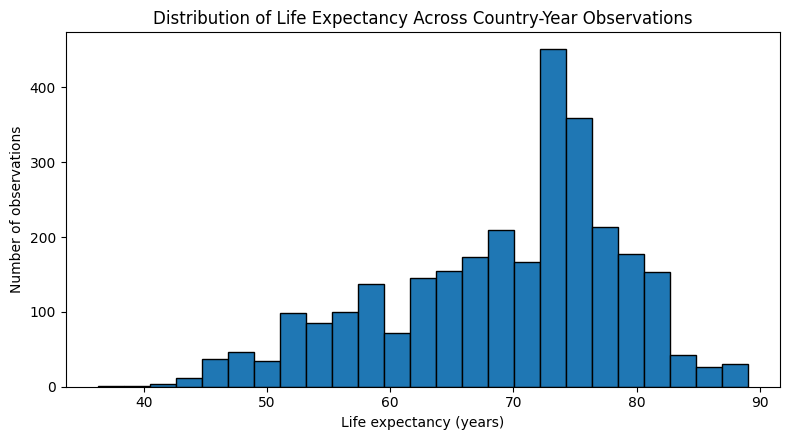

Mean = 69.22 years; median = 72.10 years.
Interpretation: compare the mean and median, and inspect the plot rather than relying on one number alone.


In [4]:
# Distribution plot: inspect spread and possible skew/outliers.
plt.figure(figsize=(8, 4.5))
plt.hist(le, bins=25, edgecolor="black")
plt.title("Distribution of Life Expectancy Across Country-Year Observations")
plt.xlabel("Life expectancy (years)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

print(f"Mean = {le.mean():.2f} years; median = {le.median():.2f} years.")
print("Interpretation: compare the mean and median, and inspect the plot rather than relying on one number alone.")

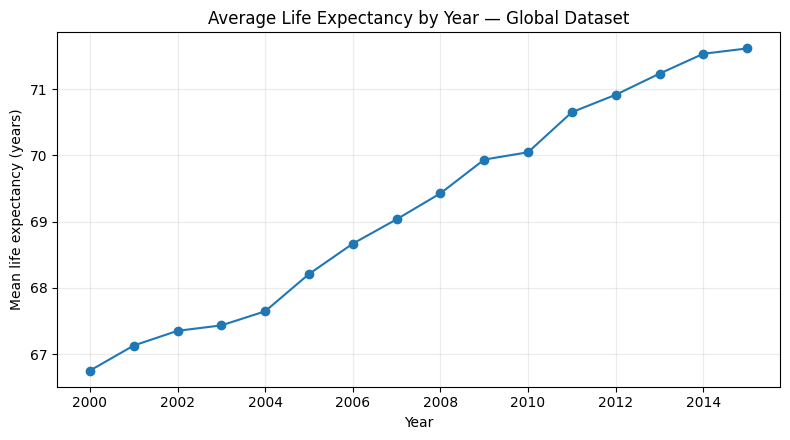

,Year,Life expectancy
0,2000,66.75
1,2001,67.13
2,2002,67.35
3,2003,67.43
4,2004,67.65
5,2005,68.21
6,2006,68.67
7,2007,69.04
8,2008,69.43
9,2009,69.94


In [5]:
# Average life expectancy by year.
yearly_global = df.groupby("Year", as_index=False)["Life expectancy"].mean()
plt.figure(figsize=(8, 4.5))
plt.plot(yearly_global["Year"], yearly_global["Life expectancy"], marker="o")
plt.title("Average Life Expectancy by Year — Global Dataset")
plt.xlabel("Year")
plt.ylabel("Mean life expectancy (years)")
plt.grid(alpha=.25)
plt.tight_layout()
plt.show()
display(yearly_global.round(2))

### Interpretation
The descriptive statistics should be read as summaries of country-year observations. The median is less sensitive to extreme values than the mean. The time-series chart shows the overall direction of change, but a change in the average does not mean every country improved at the same rate.

## 4. Probabilistic Reasoning

A 95% confidence interval is used to estimate a plausible range for the population mean based on the observed data. Under the assumptions of the interval method, if the sampling procedure were repeated many times, approximately 95% of the confidence intervals constructed would contain the true population mean.

For the global dataset, the estimated mean life expectancy was 69.22 years, with a 95% confidence interval of 68.88 to 69.57 years. This suggests that the interval method estimates the population mean to lie within this range, subject to its assumptions.

However, the dataset contains repeated country-year observations rather than a simple random sample of independent observations. Records from the same country may be related across years. Consequently, the conventional confidence interval may be too narrow if this dependence is ignored. The interval should therefore be interpreted cautiously rather than as a guarantee that the true mean lies within the calculated range.

In [6]:
# Student-t confidence interval for the mean life expectancy.
n = le.count()
mean_le = le.mean()
se_le = le.std(ddof=1) / np.sqrt(n)
t_crit = stats.t.ppf(0.975, df=n-1)
ci_global = (mean_le - t_crit * se_le, mean_le + t_crit * se_le)
print(f"n = {n}")
print(f"Mean life expectancy = {mean_le:.3f} years")
print(f"Standard error = {se_le:.4f}")
print(f"95% t confidence interval = [{ci_global[0]:.3f}, {ci_global[1]:.3f}] years")

n = 2928
Mean life expectancy = 69.225 years
Standard error = 0.1760
95% t confidence interval = [68.880, 69.570] years


### Interpretation
The confidence interval communicates uncertainty around the estimated mean, not the range in which 95% of individual country-year observations fall. It does not remove the limitations created by repeated observations and missing data.

## 5. Statistical Estimation

This section estimates the difference in average life expectancy between developed and developing observations using Welch's two-sample t method. Welch's method does not require the two groups to have equal variances. Because status is a country-level classification repeated across years, the result is interpreted as a dataset-level comparison rather than a causal effect.

In [7]:
def welch_summary(a, b, label_a="Group A", label_b="Group B"):
    a = pd.Series(a).dropna().astype(float)
    b = pd.Series(b).dropna().astype(float)
    result = stats.ttest_ind(a, b, equal_var=False)
    n1, n2 = len(a), len(b)
    v1, v2 = a.var(ddof=1), b.var(ddof=1)
    df_welch = (v1/n1 + v2/n2)**2 / ((v1/n1)**2/(n1-1) + (v2/n2)**2/(n2-1))
    diff = a.mean() - b.mean()
    se_diff = np.sqrt(v1/n1 + v2/n2)
    tcrit = stats.t.ppf(.975, df_welch)
    pooled_sd = np.sqrt(((n1-1)*v1 + (n2-1)*v2) / (n1+n2-2))
    return {
        "group_A": label_a, "n_A": n1, "mean_A": a.mean(),
        "group_B": label_b, "n_B": n2, "mean_B": b.mean(),
        "difference_A_minus_B": diff, "difference_CI_low": diff-tcrit*se_diff,
        "difference_CI_high": diff+tcrit*se_diff, "t": result.statistic,
        "df_Welch": df_welch, "p_value": result.pvalue,
        "cohens_d_descriptive": diff/pooled_sd
    }

status_result = welch_summary(
    df.loc[df["Status"] == "Developed", "Life expectancy"],
    df.loc[df["Status"] == "Developing", "Life expectancy"],
    "Developed", "Developing"
)
display(pd.Series(status_result).to_frame("value"))

,value
group_A,Developed
n_A,512
mean_A,79.197852
group_B,Developing
n_B,2416
mean_B,67.111465
difference_A_minus_B,12.086386
difference_CI_low,11.59118
difference_CI_high,12.581593
t,47.868406


## 6. Hypothesis Testing

### Developed versus developing
- Null hypothesis : mean life expectancy is equal in the developed and developing observations.
- Alternative hypothesis : the means differ.
- Significance level: α = 0.05.
- Test: two-sided Welch independent-samples t-test.
- Effect size: Cohen's d is shown as a descriptive standardised difference.

In [8]:
p = status_result["p_value"]
print(f"Welch t({status_result['df_Welch']:.2f}) = {status_result['t']:.3f}, p = {p:.4g}")
print(f"Mean difference (Developed − Developing) = {status_result['difference_A_minus_B']:.3f} years")
print(f"95% CI for difference = [{status_result['difference_CI_low']:.3f}, {status_result['difference_CI_high']:.3f}]")
print(f"Descriptive Cohen's d = {status_result['cohens_d_descriptive']:.3f}")
print("Decision:", "Reject H0 at alpha = 0.05." if p < .05 else "Do not reject H0 at alpha = 0.05.")

Welch t(1807.03) = 47.868, p = 0
Mean difference (Developed − Developing) = 12.086 years
95% CI for difference = [11.591, 12.582]
Descriptive Cohen's d = 1.448
Decision: Reject H0 at alpha = 0.05.


## 7. Correlation & Association

Pearson's correlation coefficient (\(r\)) measures the direction and strength of a linear association between two numerical variables. A positive value indicates that the variables tend to increase together, while a negative value indicates that one tends to decrease as the other increases. Values closer to \(+1\) or \(-1\) indicate stronger linear associations, while values closer to zero indicate weaker linear associations.

The coefficient of determination (\(r^2\)) is also reported as a measure of shared linear variation. It should not be interpreted as the percentage of life expectancy caused by the predictor, because correlation alone does not establish causation.

In the global dataset, schooling had a positive correlation with life expectancy (\(r = 0.752\)), while adult mortality (\(r = -0.696\)) and HIV/AIDS (\(r = -0.557\)) had negative correlations with life expectancy. In the SADC dataset, the corresponding correlations were \(r = 0.588\), \(r = -0.500\) and \(r = -0.676\), respectively.

Scatterplots were used to examine the direction and approximate linearity of these relationships, as well as possible clusters and influential observations. The results should be interpreted cautiously because confounding factors, differences between countries, measurement quality and repeated country-year observations may influence the observed associations.

,predictor,n,Pearson_r,r_squared,p_value
0,Schooling,2768,0.7520,0.5655,<0.001
1,Adult Mortality,2928,-0.6964,0.4849,<0.001
2,HIV/AIDS,2928,-0.5566,0.3098,<0.001


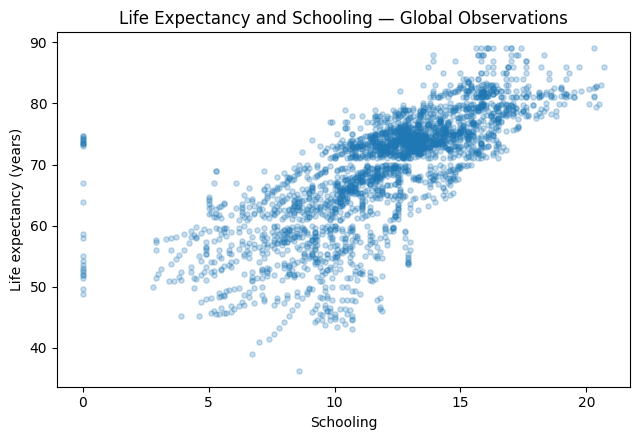

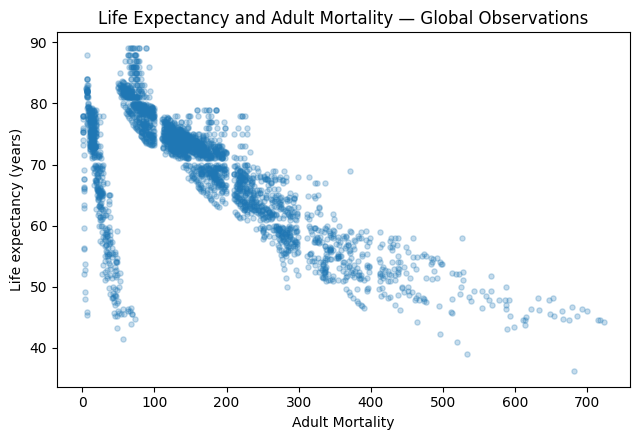

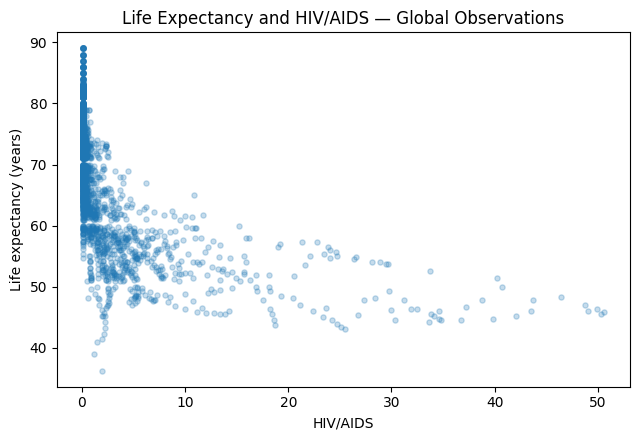

In [9]:
# Global Pearson correlations with pairwise complete observations.
predictors = ["Schooling", "Adult Mortality", "HIV/AIDS"]
corr_rows = []
for x in predictors:
    pair = df[[x, "Life expectancy"]].dropna()
    r, p = stats.pearsonr(pair[x], pair["Life expectancy"])
    corr_rows.append({
        "predictor": x, "n": len(pair), "Pearson_r": r,
        "r_squared": r*r, "p_value": p
    })
global_corr = pd.DataFrame(corr_rows)
global_corr_display = global_corr.copy()
global_corr_display["p_value"] = global_corr_display["p_value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.4f}")
display(global_corr_display.round({"Pearson_r": 4, "r_squared": 4}))

for x in predictors:
    pair = df[[x, "Life expectancy"]].dropna()
    plt.figure(figsize=(6.5, 4.5))
    plt.scatter(pair[x], pair["Life expectancy"], alpha=.25, s=14)
    plt.title(f"Life Expectancy and {x} — Global Observations")
    plt.xlabel(x)
    plt.ylabel("Life expectancy (years)")
    plt.tight_layout()
    plt.show()

## Interpretation
1. Schooling and Life Expectancy
The scatterplot shows a positive association between schooling and life expectancy. This means that countries with higher average years of schooling generally tend to have higher life expectancy. The relationship appears approximately linear overall, although some points may be spread away from the general trend. The global correlation is \(r=0.752\), while the SADC correlation is \(r=0.588\), showing that the positive association is weaker in SADC.

This difference may reflect differences in education access, poverty, healthcare services and living conditions between countries. However, the scatterplot alone cannot establish which factors explain the relationship. Repeated observations from the same countries and possible differences in data quality may also influence the results.

2. Adult Mortality and Life Expectancy
The scatterplot shows a negative association between adult mortality and life expectancy. Countries with higher adult mortality generally tend to have lower life expectancy. The relationship appears approximately linear overall, although the points may show some variation and possible outliers. The global correlation is \(r=-0.696\), compared with \(r=-0.500\) in SADC, indicating a weaker negative association in the regional data.

Possible explanations include differences in disease burden, access to healthcare, population age structure and injury rates. Differences in reporting quality may also affect the pattern. These are possible explanations rather than proven causes, and the association does not mean that adult mortality alone determines life expectancy.

3. HIV/AIDS and Life Expectancy
The scatterplot shows a negative association between HIV/AIDS and life expectancy. Higher recorded HIV/AIDS values generally correspond to lower life expectancy. The relationship appears approximately linear overall, but there may be noticeable variation between observations. The global correlation is \(r=-0.557\), while the SADC correlation is \(r=-0.676\). This indicates that the negative association is stronger in SADC than in the global dataset.

The stronger regional relationship may reflect the historical impact of the HIV/AIDS epidemic in Southern Africa. Changes in access to antiretroviral treatment during the study period may also provide relevant context. However, the correlation cannot isolate the effect of treatment or establish that HIV/AIDS alone explains differences in life expectancy.

## 8. Synthesis & Recommendations

### Three Global Findings

The analysis selects three relationships for regional follow-up because they are substantively interpretable and relevant to public health and development: schooling, adult mortality and HIV/AIDS. Selection is not based only on choosing the largest correlation or smallest p-value.

1. **Schooling and life expectancy:** The global association is positive. This motivates checking whether schooling remains positively associated with life expectancy within SADC, where education access and health systems differ among countries.
2. **Adult mortality and life expectancy:** The global association is negative. This motivates checking whether countries and years with higher adult mortality also tend to have lower life expectancy in SADC.
3. **HIV/AIDS and life expectancy:** The global association is negative. This is especially relevant to the region because HIV/AIDS has had major public-health implications in Southern Africa; the analysis should test the association rather than assume the historical story explains all country differences.

These findings describe associations in the dataset. Any recommendation should be framed as a reason to investigate services, education and health outcomes further—not as proof that changing one variable alone will produce a specific change in life expectancy.

## 9. Limitations & Reflection

### Statistical limitations
- Repeated annual records for the same countries may violate independence assumptions in simple tests and confidence intervals.
- Missing values mean some analyses use different sample sizes; complete-case analysis can introduce bias if missingness is systematic.
- Pearson correlation detects linear association and can be influenced by outliers. Country averages are included as a robustness check, but only 16 SADC countries are available.
- National-level averages cannot describe differences by sex, income, location or other subgroups within countries.
- The dataset ends in 2015 and should not be presented as a description of current conditions.

### Ethics and responsible use
1. **Avoid causal claims:** correlation does not prove that schooling, mortality or HIV/AIDS alone caused a change in life expectancy.
2. **Avoid stereotyping:** national averages hide inequalities and should not be used to label populations or countries as inherently better or worse.
3. **Acknowledge data quality:** reported indicators may differ in completeness, definition and reliability between countries and years.
4. **Prevent misuse:** communicate uncertainty and context, and do not use the results as the sole basis for decisions about individuals or communities.
5. **Respect the client question:** these data can describe patterns but cannot answer every policy question or identify individual-level causes.

### Reflection
The strongest analytical lesson is that a result can be statistically clear yet still require careful interpretation. A defensible report presents effect size, uncertainty, data limitations and context alongside p-values.

# Transition: Three Global Findings

Before moving to the regional analysis, three important relationships were identified in the global dataset. These relationships were selected because they help explain differences in life expectancy and allow meaningful comparisons between the global population and SADC countries.

Finding 1: Schooling and Life Expectancy
- Relationship: Positive association.
- Global statistic: Pearson's correlation coefficient was \(r = 0.752\), indicating a strong positive relationship. The coefficient of determination was \(r^2 = 0.565\), meaning that approximately 56.5% of the variation in life expectancy is statistically associated with its linear relationship with schooling in the observed data.
- Why this finding matters: Education may be linked to health knowledge, employment opportunities and access to resources that support better health. Understanding this relationship can help inform education and public health policies.
- Question to test in SADC: Is the relationship between schooling and life expectancy also positive in SADC, and is it weaker or stronger than the global relationship?

Finding 2: Adult Mortality and Life Expectancy
- Relationship: Negative association.
- Global statistic: Pearson's correlation coefficient was \(r = -0.696\), indicating a strong negative relationship. The coefficient of determination was \(r^2 = 0.485\), meaning that approximately 48.5% of the variation in life expectancy is statistically associated with its linear relationship with adult mortality.
- Why this finding matters: Adult mortality is an important public health indicator. Examining its relationship with life expectancy may help identify the importance of disease prevention, healthcare access and other public health interventions.
- Question to test in SADC: Does adult mortality have a negative relationship with life expectancy in SADC, and is the relationship weaker or stronger than the global pattern?

Finding 3: HIV/AIDS and Life Expectancy
- Relationship: Negative association.
- Global statistic: Pearson's correlation coefficient was \(r = -0.557\), indicating a moderate negative relationship. The coefficient of determination was \(r^2 = 0.310\), meaning that approximately 31.0% of the variation in life expectancy is statistically associated with its linear relationship with HIV/AIDS in the observed data.
- Why this finding matters: HIV/AIDS has been an important public health concern, particularly in Southern Africa. Investigating this relationship regionally may help show whether the global pattern is also evident in SADC.
- Question to test in SADC: Is the negative relationship between HIV/AIDS and life expectancy stronger in SADC than globally, and what regional factors might help explain the difference?

# Q2 — SADC Regional Investigation

## SADC data preparation and coverage

The requested 16 SADC members are Angola, Botswana, Comoros, Democratic Republic of the Congo, Eswatini, Lesotho, Madagascar, Malawi, Mauritius, Mozambique, Namibia, Seychelles, South Africa, Tanzania, Zambia and Zimbabwe. The dataset uses the historical labels `Swaziland` and `United Republic of Tanzania`; these are mapped to Eswatini and Tanzania for filtering. The dataset contains 16 years for each of the 16 countries, giving 256 country-year observations. The analysis does not omit any requested member after name harmonisation.

In [10]:
sadc_countries = [
    "Angola", "Botswana", "Comoros", "Democratic Republic of the Congo",
    "Eswatini", "Lesotho", "Madagascar", "Malawi", "Mauritius",
    "Mozambique", "Namibia", "Seychelles", "South Africa", "Tanzania",
    "Zambia", "Zimbabwe"
]
sadc = df[df["Country"].isin(sadc_countries)].copy()
outside_sadc = df[~df["Country"].isin(sadc_countries)].copy()
found = sorted(sadc["Country"].unique())
missing_countries = sorted(set(sadc_countries) - set(found))
print("SADC countries found:", len(found), found)
print("Requested countries not found after name harmonisation:", missing_countries)
print("SADC observations:", len(sadc), "| non-SADC observations:", len(outside_sadc))
display(sadc.groupby("Country")["Life expectancy"].agg(["count","mean","median","std"]).sort_values("mean", ascending=False).round(2))

SADC countries found: 16 ['Angola', 'Botswana', 'Comoros', 'Democratic Republic of the Congo', 'Eswatini', 'Lesotho', 'Madagascar', 'Malawi', 'Mauritius', 'Mozambique', 'Namibia', 'Seychelles', 'South Africa', 'Tanzania', 'Zambia', 'Zimbabwe']
Requested countries not found after name harmonisation: []
SADC observations: 256 | non-SADC observations: 2682


,count,mean,median,std
Country,,,,
Mauritius,16,72.71,72.75,1.14
Seychelles,16,72.38,72.20,0.39
Madagascar,16,62.74,63.05,2.88
Comoros,16,61.58,61.55,1.89
Namibia,16,60.40,60.85,4.45
South Africa,16,57.50,56.25,4.19
Botswana,16,56.05,57.20,7.33
Tanzania,16,56.01,56.55,4.73
Democratic Republic of the Congo,16,55.69,56.00,2.81


## SADC descriptive patterns

,SADC life expectancy
n,256.000
mean,56.991
median,56.500
sd,8.369
q1,50.750
q3,62.225
min,43.100
max,74.600


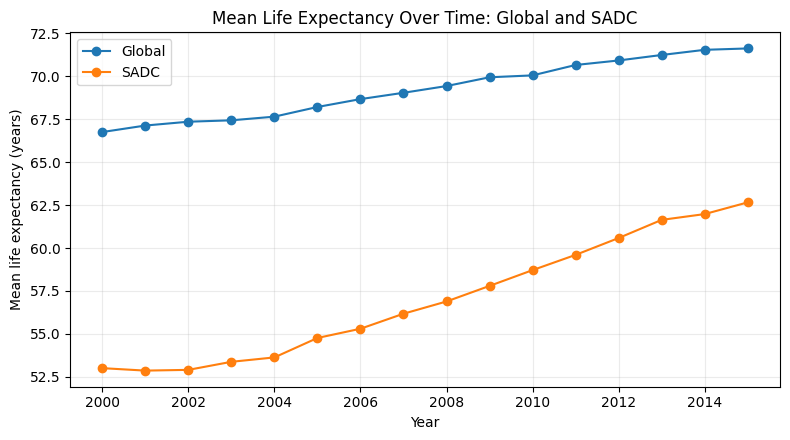

,Year,Life expectancy
0,2000,53.01
1,2001,52.86
2,2002,52.91
3,2003,53.38
4,2004,53.63
5,2005,54.76
6,2006,55.30
7,2007,56.18
8,2008,56.89
9,2009,57.79


In [11]:
sadc_le = sadc["Life expectancy"].dropna()
sadc_summary = {
    "n": len(sadc_le), "mean": sadc_le.mean(), "median": sadc_le.median(),
    "sd": sadc_le.std(ddof=1), "q1": sadc_le.quantile(.25),
    "q3": sadc_le.quantile(.75), "min": sadc_le.min(), "max": sadc_le.max()
}
display(pd.Series(sadc_summary, name="SADC life expectancy").to_frame().round(3))

yearly_sadc = sadc.groupby("Year", as_index=False)["Life expectancy"].mean()
plt.figure(figsize=(8, 4.5))
plt.plot(yearly_global["Year"], yearly_global["Life expectancy"], marker="o", label="Global")
plt.plot(yearly_sadc["Year"], yearly_sadc["Life expectancy"], marker="o", label="SADC")
plt.title("Mean Life Expectancy Over Time: Global and SADC")
plt.xlabel("Year")
plt.ylabel("Mean life expectancy (years)")
plt.legend()
plt.grid(alpha=.25)
plt.tight_layout()
plt.show()
display(yearly_sadc.round(2))

### SADC versus non-SADC hypothesis test
- Null hypothesis: mean life expectancy is equal for SADC and non-SADC country-year observations.
- Alternative hypothesis: the means differ.
- α = 0.05; two-sided Welch t-test.
- This comparison is descriptive, not causal. SADC observations are part of the global dataset, so the comparison uses the non-SADC subset as the reference group rather than comparing SADC against a global group that includes itself.

In [12]:
sadc_test = welch_summary(
    sadc["Life expectancy"], outside_sadc["Life expectancy"],
    "SADC", "Non-SADC"
)
display(pd.Series(sadc_test).to_frame("value"))
print(f"Welch t({sadc_test['df_Welch']:.2f}) = {sadc_test['t']:.3f}, p = {sadc_test['p_value']:.4g}")
print(f"Mean difference (SADC − non-SADC) = {sadc_test['difference_A_minus_B']:.3f} years")
print(f"95% CI = [{sadc_test['difference_CI_low']:.3f}, {sadc_test['difference_CI_high']:.3f}]")
print(f"Descriptive Cohen's d = {sadc_test['cohens_d_descriptive']:.3f}")
print("Decision:", "Reject H0 at alpha = 0.05." if sadc_test["p_value"] < .05 else "Do not reject H0 at alpha = 0.05.")

,value
group_A,SADC
n_A,256
mean_A,56.991406
group_B,Non-SADC
n_B,2672
mean_B,70.397006
difference_A_minus_B,-13.4056
difference_CI_low,-14.487591
difference_CI_high,-12.323609
t,-24.37827


Welch t(311.22) = -24.378, p = 3.711e-74
Mean difference (SADC − non-SADC) = -13.406 years
95% CI = [-14.488, -12.324]
Descriptive Cohen's d = -1.534
Decision: Reject H0 at alpha = 0.05.


## Retesting the three global findings in SADC

The same predictors, Pearson correlation method and pairwise complete-case rule are used so the regional and global results are comparable. Correlation coefficients should be compared for direction and magnitude, not only p-values; sample sizes differ greatly between the global and regional analyses.

,predictor,n_global,Pearson_r,r_squared,p_value,n_SADC,SADC_r,SADC_r_squared,SADC_p_value,direction_matches,absolute_r_difference
0,Schooling,2768,0.7520,0.5655,<0.001,224,0.5875,0.3451,<0.001,True,0.1645
1,Adult Mortality,2928,-0.6964,0.4849,<0.001,256,-0.4999,0.2499,<0.001,True,0.1964
2,HIV/AIDS,2928,-0.5566,0.3098,<0.001,256,-0.6761,0.4571,<0.001,True,0.1195


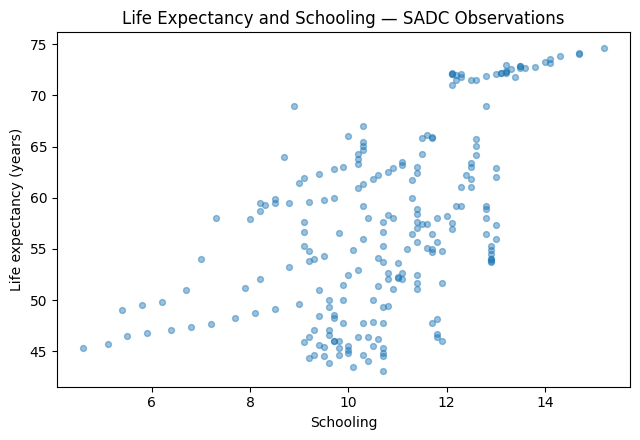

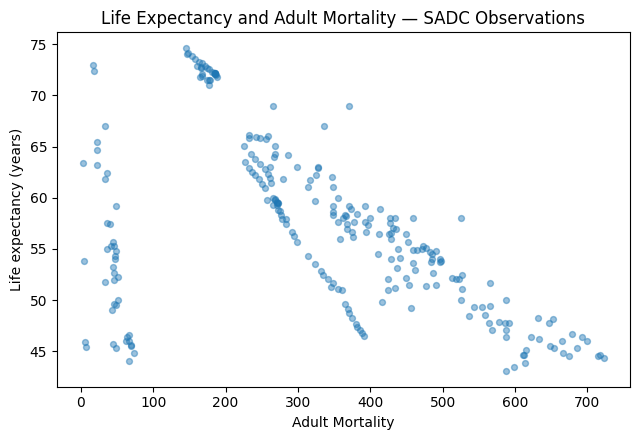

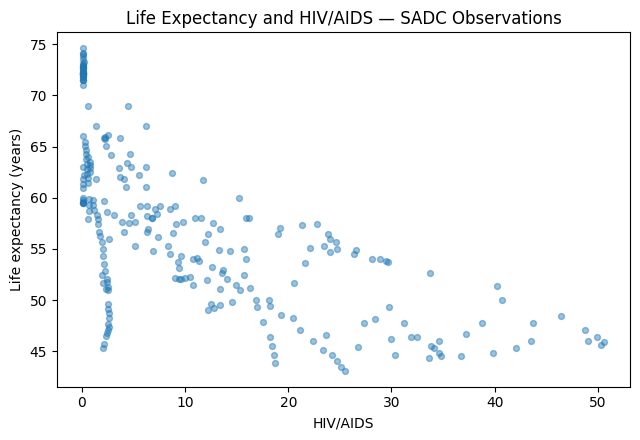

In [13]:
regional_rows = []
for x in predictors:
    pair = sadc[[x, "Life expectancy"]].dropna()
    r, p = stats.pearsonr(pair[x], pair["Life expectancy"])
    regional_rows.append({"predictor": x, "n": len(pair), "SADC_r": r,
                          "SADC_r_squared": r*r, "SADC_p_value": p})
sadc_corr = pd.DataFrame(regional_rows)
comparison = global_corr.merge(sadc_corr, on="predictor", suffixes=("_global", "_SADC"))
comparison["direction_matches"] = np.sign(comparison["Pearson_r"]) == np.sign(comparison["SADC_r"])
comparison["absolute_r_difference"] = (comparison["SADC_r"] - comparison["Pearson_r"]).abs()
comparison_display = comparison.copy()
for col in ["p_value", "SADC_p_value"]:
    comparison_display[col] = comparison_display[col].map(lambda p: "<0.001" if p < 0.001 else f"{p:.4f}")
display(comparison_display.round({"Pearson_r": 4, "r_squared": 4, "SADC_r": 4, "SADC_r_squared": 4, "absolute_r_difference": 4}))

for x in predictors:
    pair = sadc[[x, "Life expectancy"]].dropna()
    plt.figure(figsize=(6.5, 4.5))
    plt.scatter(pair[x], pair["Life expectancy"], alpha=.45, s=18)
    plt.title(f"Life Expectancy and {x} — SADC Observations")
    plt.xlabel(x)
    plt.ylabel("Life expectancy (years)")
    plt.tight_layout()
    plt.show()

# Interpretation of the Three Global Relationships in SADC
## 1. Schooling
The relationship between schooling and life expectancy in SADC remained positive, matching the global pattern. The global Pearson correlation was \(r=0.752\), while the SADC correlation was \(r=0.587\). This indicates that the association was moderately strong in SADC but weaker than the strong positive global relationship. The corresponding \(r^2\) values were approximately 56.5% globally and 34.5% in SADC, describing the proportion of variation associated with each bivariate linear relationship.

Several factors may help explain this difference. Access to education varies between countries and communities, while poverty may limit people's ability to remain in school and access nutritious food, safe housing and healthcare. Differences in health-service availability and economic development may also influence life expectancy independently of schooling. Furthermore, the SADC group contains countries with different population sizes, education systems and health conditions, which may affect the overall correlation. These are possible explanations rather than effects established by this analysis. The results suggest that schooling is an important indicator to investigate alongside wider socioeconomic and public-health conditions, but they do not prove that additional schooling directly causes longer life expectancy.
##2. Adult mortality
The relationship between adult mortality and life expectancy remained negative in SADC, consistent with the global finding. The global correlation was \(r=-0.696\), compared with \(r=-0.500\) in SADC. This means that higher adult mortality tended to be associated with lower life expectancy in both datasets, although the association was weaker in SADC. The corresponding \(r^2\) values were approximately 48.5% globally and 25.0% in SADC.

The difference in strength may reflect the diverse health and social conditions across SADC countries. Disease burdens, injuries, access to healthcare and the availability of timely treatment may vary considerably. Age structure can also influence mortality patterns, while differences in the completeness and quality of health reporting may affect the recorded values. These factors could contribute to the observed relationship, but the correlation analysis does not identify which explanation is most important. The findings support examining adult mortality as a useful indicator when studying life expectancy, while recognising that the relationship is not necessarily the same across all countries or years.
## 3. HIV/AIDS
The relationship between the HIV/AIDS indicator and life expectancy remained negative in SADC and was stronger in magnitude than the global relationship. The global Pearson correlation was \(r=-0.557\), whereas the SADC correlation was \(r=-0.676\). The corresponding \(r^2\) values were approximately 31.0% globally and 45.7% in SADC. This suggests that the negative linear association was more pronounced in the SADC observations.

This finding is relevant in light of Southern Africa's historical HIV/AIDS burden during the period covered by the dataset. The years 2000–2015 also included major expansions in antiretroviral treatment (ART) access in the region. Improved access to treatment is important historical context when interpreting changes in HIV-related health outcomes and life expectancy. However, the dataset's correlation analysis does not isolate the effect of treatment or establish that treatment expansion caused the observed changes. Establishing such an effect would require additional evidence, including treatment coverage, HIV prevalence, mortality trends and the timing of policy changes. The stronger negative association therefore identifies a relationship that deserves further investigation rather than providing a complete explanation of regional life expectancy.
## 4. SADC-specific patterns: Island and mainland countries
For this comparison, the island group is defined in advance as Comoros, Madagascar, Mauritius and Seychelles, while the mainland group consists of the remaining 12 SADC countries. This classification provides a consistent basis for comparing the two groups, although each group contains a relatively small number of countries, particularly the island group.

The dataset shows substantial differences in average life expectancy among SADC countries. For example, Mauritius and Seychelles had some of the highest country-average values, while Lesotho and Angola had some of the lowest. These individual results demonstrate regional diversity, but they do not establish that island countries generally have higher life expectancy than mainland countries. A formal comparison would need to calculate the mean for each group, estimate the difference and its uncertainty, and account for the small number of countries and repeated observations over time.

Possible contextual factors include differences in economic structure, healthcare systems, population distribution, transport and access to medical services. However, these are potential explanations, not conclusions demonstrated by the dataset. The analysis does not establish that geographical location or island status causes differences in life expectancy. The island–mainland comparison should therefore be treated as an exploratory question, with any conclusions reported alongside the group estimates and their uncertainty.
Overall interpretation
All three global associations retained their original directions in SADC. Schooling was positively associated with life expectancy, while adult mortality and the HIV/AIDS indicator were negatively associated with it. However, schooling and adult mortality had weaker correlations in SADC, whereas the HIV/AIDS association was stronger. These differences highlight the importance of analysing regional data separately rather than assuming that global relationships apply equally to every region.

The findings should be interpreted cautiously because the dataset contains repeated country-year observations, missing values and national averages that can conceal differences within populations. The analysis also covers 2000–2015 rather than current conditions. Further work should examine country-specific trends, compare island and mainland groups using explicit statistical tests, and incorporate additional contextual data where appropriate. Overall, the results identify meaningful statistical associations and questions for further research, but they do not establish causation or explain every difference in life expectancy across SADC.

## Country-level robustness check

To reduce the risk that repeated yearly rows alone drive the correlations, the following check calculates one average per country and correlates country-average life expectancy with country-average values of the three indicators. This is a different unit of analysis, so its coefficients should not be treated as interchangeable with the pooled country-year correlations.

In [14]:
country_avg_global = df.groupby("Country")[["Life expectancy"] + predictors].mean(numeric_only=True)
country_avg_sadc = sadc.groupby("Country")[["Life expectancy"] + predictors].mean(numeric_only=True)

def country_corr_table(country_avg, label):
    rows = []
    for x in predictors:
        pair = country_avg[[x, "Life expectancy"]].dropna()
        r, p = stats.pearsonr(pair[x], pair["Life expectancy"])
        rows.append({"scope": label, "predictor": x, "countries_n": len(pair),
                     "Pearson_r": r, "r_squared": r*r, "p_value": p})
    return pd.DataFrame(rows)

robustness = pd.concat([
    country_corr_table(country_avg_global, "Global country averages"),
    country_corr_table(country_avg_sadc, "SADC country averages")
], ignore_index=True)
display(robustness.round(5))

,scope,predictor,countries_n,Pearson_r,r_squared,p_value
0,Global country averages,Schooling,173,0.79446,0.63116,0.00000
1,Global country averages,Adult Mortality,183,-0.89644,0.80361,0.00000
2,Global country averages,HIV/AIDS,183,-0.58715,0.34475,0.00000
3,SADC country averages,Schooling,14,0.61695,0.38063,0.01876
4,SADC country averages,Adult Mortality,16,-0.74703,0.55806,0.00088
5,SADC country averages,HIV/AIDS,16,-0.62231,0.38727,0.01004


SADC-Specific Patterns
The SADC subset contains 256 country-year observations covering all 16 countries in the required regional list from 2000 to 2015. The results show considerable variation in life expectancy between countries, an increase in the regional average over time, and associations with schooling, adult mortality and HIV/AIDS that remain in the same direction as the global relationships. However, these patterns differ in strength and should be interpreted in the context of the region's diverse social, economic and public-health conditions.
1. Differences in average life expectancy between SADC countries
Average life expectancy varied substantially across the 16 SADC countries. When each country's observations from 2000–2015 were averaged, Mauritius had the highest mean at approximately 72.71 years, closely followed by Seychelles at 72.38 years. Lesotho had the lowest mean at 48.78 years, followed by Angola at 49.02 years. The difference between the highest and lowest country averages was therefore approximately 23.93 years.

This spread shows why a single SADC average cannot adequately represent every country. Countries within the same regional grouping can have very different health outcomes and development circumstances. The observed differences identify areas for further investigation, but these averages alone cannot establish why particular countries had higher or lower life expectancy.
2. Changes in the SADC regional average over time
The mean life expectancy across available SADC country-year observations increased from approximately 53.01 years in 2000 to 62.66 years in 2015, a rise of about 9.65 years. This indicates an improvement in the regional average over the period covered by the dataset.

However, the regional trend does not mean that every SADC country improved by the same amount or followed the same pattern. A regional average can increase even when some countries improve more slowly, experience periods of decline, or start from substantially different levels. Further examination of individual country trends would be needed to identify which countries contributed most to the overall change.
3. Do the three global associations hold in SADC?
The three selected relationships retained the same direction in SADC as in the global dataset, although their strengths differed.
Variable associated with life expectancy	Global Pearson \(r\)	SADC Pearson \(r\)	Regional interpretation
Schooling	+0.752	+0.587	Positive, but weaker in SADC
Adult mortality	−0.696	−0.500	Negative, but weaker in SADC
HIV/AIDS indicator	−0.557	−0.676	Negative and stronger in SADC

Schooling: The positive SADC correlation (\(r=0.587\)) indicates that country-year observations with more schooling tended to have higher life expectancy. The relationship is weaker than the global correlation of \(r=0.752\). This suggests that schooling alone does not capture all the differences associated with life expectancy within SADC.

Adult mortality: The negative SADC correlation (\(r=-0.500\)) indicates that higher adult mortality tended to be associated with lower life expectancy. Although the direction agrees with the global result, the relationship is weaker in SADC than globally. This difference may reflect the influence of other health, economic and social conditions, but the correlation analysis does not identify which factors account for the difference.

HIV/AIDS: The SADC correlation was more strongly negative (\(r=-0.676\)) than the global correlation (\(r=-0.557\)). This indicates a stronger negative linear association in the SADC country-year observations. Given the region's historical HIV/AIDS burden, this finding is relevant for public-health investigation. Nevertheless, the correlation does not establish that HIV/AIDS alone explains the regional life-expectancy pattern.
4. Pooled country-year patterns versus country-average patterns
The pooled correlations use individual country-year observations, whereas country-average correlations first calculate each country's mean values and then compare countries. These approaches answer different questions.

The country-average correlations in SADC were approximately:
Relationship	Pooled country-year \(r\)	Country-average \(r\)
Schooling and life expectancy	+0.587	+0.617
Adult mortality and life expectancy	−0.500	−0.747
HIV/AIDS and life expectancy	−0.676	−0.622

The schooling association was similar under both approaches. The adult-mortality association was stronger when comparing country averages, while the HIV/AIDS association was somewhat weaker. This shows that the apparent strength of a relationship depends partly on whether the analysis compares observations over time or differences between countries.

The country-average analysis includes only 14 countries for schooling because of missing data, compared with 16 for adult mortality and HIV/AIDS. Consequently, the schooling result uses a smaller subset and should be compared with the pooled result cautiously. Neither approach establishes causation, and the pooled observations are not fully independent because countries recur across years.
5. Contextual interpretation: HIV/AIDS, treatment and regional diversity
The stronger negative pooled association between the HIV/AIDS indicator and life expectancy in SADC makes HIV/AIDS an important area for further investigation. The period from 2000 to 2015 also overlaps with major changes in HIV prevention, diagnosis and antiretroviral treatment access in Southern Africa. These developments provide relevant historical context for interpreting the data.

However, the analysis presented here does not directly test the effect of antiretroviral therapy rollout. Establishing whether treatment access corresponds with changes in life expectancy would require additional evidence, such as country-level treatment coverage, HIV prevalence and mortality trends over time. Similarly, although Mauritius and Seychelles had higher country-average life expectancy than many mainland countries in this dataset, the results do not demonstrate that island status explains this difference. That question would require a more carefully designed comparison and consideration of other national characteristics.
6. Why the regional mean has limitations
The SADC mean combines countries with substantially different average life expectancies. It also describes national observations rather than the circumstances of every individual resident. Differences associated with income, location, gender, healthcare access and other social conditions may be hidden within national averages.

The analysis is also limited by missing observations, the 2000–2015 time period and the repeated-measures structure of the dataset. Correlations summarise associations between variables but do not establish causal relationships or explain every country-specific change. Further analysis should therefore examine individual country trends and use methods that account for repeated observations when making statistical inferences.
Overall regional finding
The SADC investigation shows that the three global associations remain in the same direction within the region, but their strengths differ. Schooling and adult mortality have weaker pooled correlations in SADC than globally, while the negative HIV/AIDS association is stronger. At the same time, average life expectancy increased across the regional observations between 2000 and 2015, and the difference between the highest and lowest country averages was nearly 24 years.

These findings support regional and country-specific public-health investigation rather than relying on a single global or SADC average. Education, adult mortality and HIV/AIDS indicators are useful variables for understanding patterns in life expectancy, but decisions about interventions should also consider country-specific evidence, healthcare conditions and other social determinants. The results should be treated as evidence of association and variation—not proof that any single factor caused the observed outcomes.

## Final Conclusion

This investigation examined global life expectancy from 2000 to 2015 and assessed whether relationships between life expectancy, schooling, adult mortality and HIV/AIDS indicators were also evident in the Southern African Development Community (SADC). The results reveal substantial differences in life expectancy across regions and meaningful statistical associations between life expectancy and the three selected variables.

Globally, the mean life expectancy was 69.22 years, with a 95% confidence interval of 68.88 to 69.57 years. This interval estimates the population mean under the assumptions of the confidence-interval method. However, because the dataset contains repeated observations for countries across multiple years, the interval should be interpreted cautiously rather than as accounting fully for the dependence between observations.

The global correlation analysis identified three important relationships. First, schooling had a strong positive correlation with life expectancy (\(r=0.752\), \(r^2=0.565\)). Approximately 56.5% of the variation in life expectancy was associated with its linear relationship with schooling in the observed data. Second, adult mortality had a strong negative correlation with life expectancy (\(r=-0.696\), \(r^2=0.485\)), indicating that higher adult mortality tended to occur alongside lower life expectancy. The squared correlation was approximately 48.5%. Third, the HIV/AIDS indicator had a negative correlation with life expectancy (\(r=-0.557\), \(r^2=0.310\)), with approximately 31.0% of the observed variation associated with this linear relationship. These \(r^2\) values describe bivariate linear associations; they do not represent the proportion of life expectancy that a variable independently causes or explains after accounting for other factors.

The regional comparison showed that mean life expectancy in SADC was 56.99 years, compared with 70.40 years outside SADC. The estimated difference, calculated as SADC minus non-SADC, was −13.41 years. A Welch independent-samples t-test indicated a statistically significant difference, \(t(311.22)=-24.38\), \(p<0.001\). The effect size was large (Cohen’s \(d=-1.53\)), indicating that the difference was substantial relative to the pooled standard deviation. Nevertheless, the test treats country-year observations as independent, so the reported significance may overstate the strength of the evidence if within-country dependence is not accounted for.

All three global relationships were also observed in SADC, although their strengths differed. Schooling remained positively correlated with life expectancy (\(r=0.587\), \(r^2=0.345\)), while adult mortality remained negatively correlated (\(r=-0.500\), \(r^2=0.250\)). The negative association between the HIV/AIDS indicator and life expectancy was stronger in SADC (\(r=-0.676\), \(r^2=0.457\)) than in the global dataset (\(r=-0.557\)). These differences suggest that the relationships vary by region and that global averages may not fully represent the circumstances of Southern African countries. The stronger HIV/AIDS association warrants further investigation using historical, public-health and treatment-access evidence rather than correlation alone.

Several limitations must be considered. The dataset contains missing values, repeated observations from the same countries, and national averages that conceal inequalities within populations. The analysis is observational and does not establish causal relationships. Other factors—including healthcare access, income, sanitation, nutrition, conflict and public-health interventions—may also be related to life expectancy. In addition, the dataset covers only 2000–2015, so its results should not automatically be treated as a description of current conditions. Further analysis should consider country-level patterns, changes over time, potential confounding variables and statistical methods that account for repeated measurements.

In practical terms, the findings suggest that policymakers and public-health researchers should investigate education, adult mortality and HIV/AIDS alongside wider socioeconomic and healthcare conditions when evaluating life expectancy. The SADC results also demonstrate the importance of regional analysis: interventions and policies should be informed by country-specific evidence rather than relying exclusively on global averages. Overall, the investigation identifies statistically meaningful associations and substantial regional differences, while recognising that further analysis is needed before drawing conclusions about causes or the likely effects of particular policies.

## Appendix A: Statistical Decision Log

The table below records the analytical decisions implemented in this notebook.

In [15]:
decision_log = pd.DataFrame([
    ["Data preparation", "Trim column names and harmonise Swaziland/United Republic of Tanzania for membership matching.",
     "Prevents avoidable column-access and historical-name matching errors without altering measured values.",
     "Exclude these countries or edit measurements; rejected because both are requested SADC members."],
    ["Missing data", "Use complete cases separately for each analysis.",
     "Keeps each statistic based on observed values and makes the sample size explicit.",
     "Fill missing values with zero; rejected because zero would falsely imply a measured zero."],
    ["Descriptive statistics", "Report mean, median, standard deviation, quartiles and range.",
     "Shows centre, spread and potential skew/outliers rather than relying on one measure.",
     "Report only the mean; rejected because it hides spread and skew."],
    ["Confidence interval", "Use a 95% Student-t interval for the global mean.",
     "Population standard deviation is unknown, so estimate uncertainty using the sample standard deviation.",
     "Use a z interval; rejected because population SD is not known."],
    ["Group comparison", "Use a two-sided Welch t-test for group means.",
     "Welch's test does not require equal group variances and tests for differences in either direction.",
     "Use a pooled-variance t-test; rejected because equal variances are not guaranteed."],
    ["Global association", "Use Pearson r for schooling, adult mortality and HIV/AIDS, with scatterplots.",
     "Pearson r quantifies linear direction and strength; plots help assess linearity and influential observations.",
     "Interpret p-values alone; rejected because magnitude and shape matter."],
    ["Regional comparison", "Compare SADC with non-SADC rather than with the full global sample.",
     "Avoids putting the SADC observations in both comparison groups.",
     "Compare SADC to global including SADC; rejected because the groups would overlap."],
    ["SADC membership", "Use all 16 requested countries and harmonise two historical labels.",
     "Ensures the region is represented according to the assignment's country list.",
     "Drop countries with historical labels; rejected because this would create an avoidable coverage gap."],
    ["Robustness", "Repeat the three correlations using country averages.",
     "Checks whether the broad pattern persists when each country contributes one observation.",
     "Treat pooled rows as independent; rejected as the only analysis because countries repeat over years."],
    ["Interpretation", "Describe associations and avoid causal claims.",
     "The data are observational and may contain confounding and repeated measurements.",
     "Claim a predictor caused a change; rejected because the design does not establish causality."]
], columns=["Stage", "Decision", "Statistical justification", "Alternative considered/rejected"])
display(decision_log)

,Stage,Decision,Statistical justification,Alternative considered/rejected
0,Data preparation,Trim column names and harmonise Swaziland/Unit...,Prevents avoidable column-access and historica...,Exclude these countries or edit measurements; ...
1,Missing data,Use complete cases separately for each analysis.,Keeps each statistic based on observed values ...,Fill missing values with zero; rejected becaus...
2,Descriptive statistics,"Report mean, median, standard deviation, quart...","Shows centre, spread and potential skew/outlie...",Report only the mean; rejected because it hide...
3,Confidence interval,Use a 95% Student-t interval for the global mean.,"Population standard deviation is unknown, so e...",Use a z interval; rejected because population ...
4,Group comparison,Use a two-sided Welch t-test for group means.,Welch's test does not require equal group vari...,Use a pooled-variance t-test; rejected because...
5,Global association,"Use Pearson r for schooling, adult mortality a...",Pearson r quantifies linear direction and stre...,Interpret p-values alone; rejected because mag...
6,Regional comparison,Compare SADC with non-SADC rather than with th...,Avoids putting the SADC observations in both c...,Compare SADC to global including SADC; rejecte...
7,SADC membership,Use all 16 requested countries and harmonise t...,Ensures the region is represented according to...,Drop countries with historical labels; rejecte...
8,Robustness,Repeat the three correlations using country av...,Checks whether the broad pattern persists when...,Treat pooled rows as independent; rejected as ...
9,Interpretation,Describe associations and avoid causal claims.,The data are observational and may contain con...,Claim a predictor caused a change; rejected be...
